# SYDE 572 Assignment 2
#### Part 1(a)
#### Polynomial Basis Function

In this part, the first 100 elements of the housing dataset will be used as the training data and the remaining as test. A polynomial basis function regression will be fit to this data for degree 1 to 7 polynomials. 

In [108]:
# required libraries 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from pathlib import Path 

In [109]:
# import data 
data_path = Path("assn2 material") / "housing.data"
housing_data = np.loadtxt(data_path)

# inspect the headers of the data section 
names_path = Path("assn2 material") / "housing.names"
names_text = names_path.read_text()

# inspect the data to extract only the attribute-information section
attribute_section = (
    names_text
    .split("7. Attribute Information:")[1]
    .split("8. Missing Attribute Values:")[0]
)
print(attribute_section)




    1. CRIM      per capita crime rate by town
    2. ZN        proportion of residential land zoned for lots over 
                 25,000 sq.ft.
    3. INDUS     proportion of non-retail business acres per town
    4. CHAS      Charles River dummy variable (= 1 if tract bounds 
                 river; 0 otherwise)
    5. NOX       nitric oxides concentration (parts per 10 million)
    6. RM        average number of rooms per dwelling
    7. AGE       proportion of owner-occupied units built prior to 1940
    8. DIS       weighted distances to five Boston employment centres
    9. RAD       index of accessibility to radial highways
    10. TAX      full-value property-tax rate per $10,000
    11. PTRATIO  pupil-teacher ratio by town
    12. B        1000(Bk - 0.63)^2 where Bk is the proportion of blacks 
                 by town
    13. LSTAT    % lower status of the population
    14. MEDV     Median value of owner-occupied homes in $1000's




In [110]:
# input variables
feature_names = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT"]
column_names = feature_names + ["MEDV"]

# load dataset 
housing_data = np.loadtxt(data_path)

# convert to a table / 2d array for visualization 
housing_df = pd.DataFrame(housing_data, columns= column_names)

print("Dataset shape:", housing_data.shape)
housing_df.head()

Dataset shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


The first 13 columns of the dataset are the inputs and the final column "MEDV" representing the median value of the house is the target. 

The input features are standardized using statistics calculated from the training set: 
$$
x_{\text{normalized}}
=
\frac{x-\mu_x}{\sigma_x}
$$

This scaling is especially important for polynomial regression because otherwise powers of features with large numerical ranges can make the design matrix unstable. The test inputs are transformed using the training-set mean and standard deviation so that no test information is used during fitting. MEDV is kept in its original units of thousands of dollars, so the calculated Root Mean Squared Error (RMSE) values are also directly in thousands of dollars.

First, the dataset is loaded and split into training and test set, as guided in the assignment instructions. The data is also normalized as described above and the shape of the data is inspected, to confirm the split.

In [111]:
# seperate input and target 
X = housing_data[:, :-1]
target = housing_data[:, -1]

# split into test & train - first 100 points are train, rest are test 
X_train = X[:100]
target_train = target[:100]
X_test = X[100:]
target_test = target[100:]

# calculate normalization parameters 
X_mean = np.mean(X_train, axis = 0)
X_std = np.std(X_train, axis = 0)
# set std 1 if it is 0 from the dataset (to prevent dividing by zero) eg for CHAS data
X_std = np.where(X_std == 0, 1.0, X_std)

# normalize the input features using training-set statistics
# MEDV is intentionally kept in its original units ($1000s)
X_train = (X_train - X_mean) / X_std
X_test = (X_test - X_mean) / X_std

print("Training input shape:", X_train.shape)
print("Training target shape:", target_train.shape)
print("Testing input shape:", X_test.shape)
print("Testing target shape:", target_test.shape)

Training input shape: (100, 13)
Training target shape: (100,)
Testing input shape: (406, 13)
Testing target shape: (406,)


### Polynomial design matrix

For degree $d$, each feature generates $d$ polynomial basis functions

$$
\phi_d(\mathbf{x})
=
\left[
1,\,
x_1,x_1^2,\ldots,x_1^d,\,
x_2,x_2^2,\ldots,x_2^d,\,
\ldots,\,
x_{13},x_{13}^2,\ldots,x_{13}^d
\right]
$$

where the first value, $1$, is the bias basis function and cross-terms such as $x_1x_2$ are not included.

Because there are 13 original features and one bias term, and $d$ powers of each feature, the total number of basis functions and therefore the number of weights that must be learned is $K=1+13d$

For N input points, the transformed feature vectors are combined to form the design matrix 

$$
\Phi
=
\begin{bmatrix}
\phi_d(\mathbf{x}_1)\\
\phi_d(\mathbf{x}_2)\\
\vdots\\
\phi_d(\mathbf{x}_N)
\end{bmatrix}
\qquad
\Phi\in\mathbb{R}^{N\times K}
$$

where each row represents one input and each column represents one polynomial basis function. The model predictions are calculated using $\hat{\mathbf{t}}=\Phi\mathbf{w}$ where $\mathbf{w}$ is the vector of learned weights.

The weights are selected using ordinary least squares by minimizing the sum of squared differences between the predicted and actual training targets and the model's error is measured using root mean squared error: 

$$
\operatorname{RMS}
=
\sqrt{
\frac{1}{N}
\sum_{i=1}^{N}
(\hat{t}_i-t_i)^2
}
$$

The functions for constructing the polynomial design matrix, calculating RMS error, and fitting the polynomial regression models are defined as follows:

In [112]:
def polynomial_design_matrix(X, degree): 
    # matrix to construct the polynomial basis functions 

    # bias column allows the model to learn an intercept weight 
    columns = [np.ones((X.shape[0], 1))]

    for feature_index in range(X.shape[1]):
        feature = X[:, feature_index: feature_index+1]

        for power in range(1, degree+1): 
            # add x_j^1, x_j^2, ..., x_j^degree for the current feature
            columns.append(feature**power)
    return np.hstack(columns)

def rms_error(actual, predicted): 
    return np.sqrt(np.mean((predicted-actual)**2))

def polynomial_regression(X_train, target_train, X_test, target_test, max_degree=7): 
    # polynomial basis function regression for degree 1-7 polynomials 

    res = []
    learned_weights = {}

    for degree in range(1, max_degree+1): 
        # construct training and testing design matrices
        Phi_train = polynomial_design_matrix(X_train, degree)
        Phi_test = polynomial_design_matrix(X_test, degree)
        #calculate weights that minimize the sum of squared error 
        weights, residuals, rank, singular_values = (np.linalg.lstsq(Phi_train, target_train, rcond=None))
        # multiply the matricies to determine the predicted values 
        train_pred = Phi_train @ weights 
        test_pred = Phi_test @ weights 
        # calulate rms error 
        training_rms = rms_error(target_train, train_pred)
        testing_rms = rms_error(target_test, test_pred)
        # append results 
        res.append({
            "degree": degree, 
            "number_of_basis_functions": Phi_train.shape[1],
            "training_rms": training_rms,
            "testing_rms": testing_rms,
            "matrix_rank": rank
        })
        # store the learned weights per degree of polynomial
        learned_weights[degree] = weights
    # visualize in a table
    res_table = pd.DataFrame(res)
    return res_table, learned_weights


The polynomial-regression function is now run for degrees 1 through 7 and results are presented in the table below. No regularization is applied.

In [113]:
# data for the plot 
error_table, polynomial_weights = polynomial_regression(X_train=X_train, target_train=target_train, X_test=X_test, target_test=target_test, max_degree=7)
# MEDV was not normalized, so these errors are already in $1000s
error_table["training_rmse_1000s"] = error_table["training_rms"]

error_table["testing_rmse_1000s"] = error_table["testing_rms"]

error_table

,degree,number_of_basis_functions,training_rms,testing_rms,matrix_rank,training_rmse_1000s,testing_rmse_1000s
0,1,14,2.037201,3.644495e+01,13,2.037201,3.644495e+01
1,2,27,1.578079,1.097188e+03,25,1.578079,1.097188e+03
2,3,40,1.449098,4.867282e+04,37,1.449098,4.867282e+04
3,4,53,1.270498,2.185931e+07,48,1.270498,2.185931e+07
4,5,66,1.096636,1.835804e+10,54,1.096636,1.835804e+10
5,6,79,1.072510,5.024089e+12,60,1.072510,5.024089e+12
6,7,92,0.881467,6.879332e+15,66,0.881467,6.879332e+15


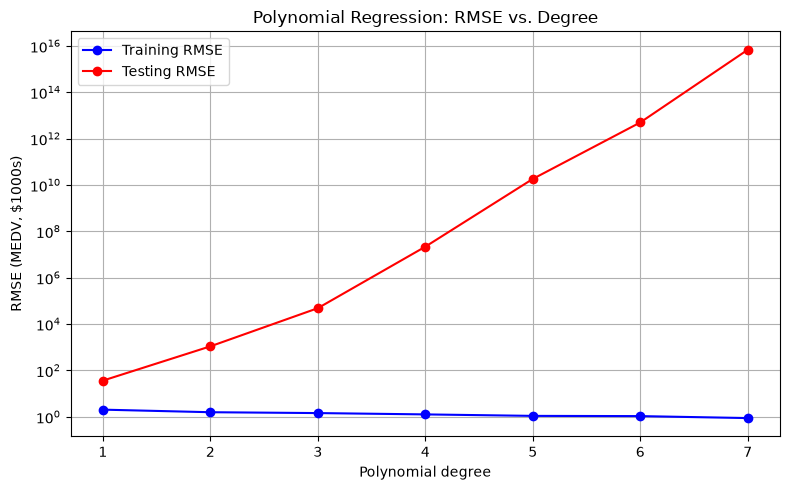

In [114]:
# plot training and testing RMSE in the original MEDV units
fig, ax = plt.subplots(figsize=(8, 5))

# training error
ax.plot(
    error_table["degree"],
    error_table["training_rmse_1000s"],
    color="blue",
    marker="o",
    label="Training RMSE"
)

# testing error
ax.plot(
    error_table["degree"],
    error_table["testing_rmse_1000s"],
    color="red",
    marker="o",
    label="Testing RMSE"
)

# errors span several orders of magnitude
ax.set_yscale("log")

# grid cosmetic changes
ax.set_title("Polynomial Regression: RMSE vs. Degree",)
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("RMSE (MEDV, $1000s)")

ax.grid(True)

ax.legend()

plt.tight_layout()
plt.show()

### Results

The training RMSE decreases as the polynomial degree increases. It falls from approximately $2.037$ thousand dollars for the degree 1 model to $0.881$ thousand dollars for the degree 7 model. This is expected because every increase in degree adds more polynomial basis functions, giving the model more flexibility so that it is able to fit the training data better.

In contrast, the testing RMSE is lowest for the degree 1 model at approximately $36.445$ thousand dollars and increases dramatically with polynomial degree. By degree 7, the testing RMSE reaches approximately $6.88\times10^{15}$ thousand dollars. Therefore, the reduction in training error does not represent improved performance on unseen test data.

These results indicate severe overfitting. The higher degree models fit the first 100 training data points very closely but do not generalize well to the remaining testing points. When testing feature values fall outside the range represented by the training data, raising them to high powers creates extremely large polynomial terms, resulting in unstable and extreme predictions.

Of the polynomial degrees considered, degree 1 has the lowest testing RMSE and therefore provides the best generalization. However, its testing RMSE of approximately $36.445$ thousand dollars is still much larger than its training RMSE, suggesting that the first 100 training points are not fully representative of the testing data and that the fitted model extrapolates poorly beyond the training range.

#### Part 1(b)

For degree 1, each normalized input feature appears linearly in the regression model:

$$
\hat t
=
w_{\mathrm{bias}}
+
\sum_{j=0}^{12}w_jx_{n,j},
$$

where $x_{n,j}$ is normalized value of feature $j$ for input $n$ and $\hat t$ is the predicted MEDV in thousands of dollars.

The model contains one bias weight and 13 feature weights. Because the bias occupies the first position of the NumPy weight vector, the weight for feature $j$ is stored at position $j+1$. Therefore, the weight for RM, feature index 5, is stored at degree_one_weights[6], while the weight for DIS, feature index 7, is stored at degree_one_weights[8].

The degree 1 weights are displayed & extracted below.

In [115]:
# extract the learned weights for the degree-1 model
degree_one_weights = polynomial_weights[1]

# labels for the bias and feature weights
weight_labels = ["bias"] + [
    f"w{index} ({feature_name})"
    for index, feature_name in enumerate(feature_names)
]

# display all learned weights
degree_one_weight_table = pd.DataFrame({
    "weight": weight_labels,
    "value": degree_one_weights
})

degree_one_weight_table

,weight,value
0,bias,2.230900e+01
1,w0 (CRIM),-1.337974e+00
2,w1 (ZN),1.229934e-01
3,w2 (INDUS),-5.310646e-01
4,w3 (CHAS),-4.440892e-16
5,w4 (NOX),1.002651e+00
6,w5 (RM),4.195634e+00
7,w6 (AGE),-2.166275e+00
8,w7 (DIS),1.071545e-02
9,w8 (RAD),-1.937782e-01


### Weights interpretation

The degree 1 model learned a weight of approximately $4.1956$ for RM, the average number of rooms per dwelling. Since RM is normalized but MEDV remains in its original units, this means that a one training standard deviation increase in RM is associated with an increase of approximately $4.196$ thousand dollars in predicted MEDV, while holding the other input features constant.

The training standard deviation of RM is approximately $0.488$ rooms. Therefore, the equivalent change per additional room is

$$
\frac{4.1956}{0.488}
\approx
8.59
$$

thousand dollars. The positive weight is reasonable because homes with more rooms would generally be expected to have higher values.

The degree 1 model learned a weight of approximately $0.01072$ for DIS, the weighted distance to five Boston employment centres. A one training standard deviation increase in DIS therefore changes the predicted MEDV by only approximately $0.01072$ thousand dollars, or about $\$10.72$, holding the other features constant.

The DIS weight is positive, although a negative relationship might initially be expected because greater distance from employment centres could reduce property values. However, the learned value is very small when compared to the others, and is almost zero, so it can be interpreted as a negligible relationship rather than a meaningful positive effect. 

Each learned weight measures the feature’s relationship with predicted MEDV while the other 12 input features are held constant. Therefore, the degree 1 model indicates that RM has a substantial positive relationship with predicted MEDV, whereas DIS has a negligible relationship.

The learned bias is approximately $22.309$ thousand dollars. Since the input features were centred using their training means, the bias represents the predicted MEDV when all normalized inputs are zero, which means when the input features are at their training set means.

#### Part 1(c)

Using $X_n(:,2)$, the second feature, means using ZN to visualize the high-dimensional polynomial regression. In NumPy, ZN is selected using column index 1. For a polynomial of degree $d$, the one-dimensional basis vector is:

$$
\boldsymbol{\phi}_d(z)
=
[1,z,z^2,\ldots,z^d]
$$

The corresponding prediction is
$$
\hat t
=
w_0+w_1z+w_2z^2+\cdots+w_dz^d
$$

Therefore, a degree-$d$ model has $K=d+1$ parameters.

For the $N=100$ training samples, the one-dimensional design matrix is

$$
\boldsymbol{\Phi}
=
\begin{bmatrix}
1 & z_1 & z_1^2 & \cdots & z_1^d \\
1 & z_2 & z_2^2 & \cdots & z_2^d \\
\vdots & \vdots & \vdots & & \vdots \\
1 & z_N & z_N^2 & \cdots & z_N^d
\end{bmatrix}
$$

The ZN values are normalized using the mean and standard deviation calculated from the training data. MEDV is kept in its original units of thousands of dollars. The first 100 samples are used to learn the polynomial weights, and the resulting curve is plotted with both the training and testing data.

Degrees 1 through 7 were initially fitted and visually inspected. Degrees 1, 4, and 7 are presented below to compare low, intermediate, and high degree polynomial models.

In [116]:
def polynomial_regression_1d_vis(X_train, target_train, X_test, target_test, degree, feature_index=1):
    # fit and visualize a 1d polynomial regression using ZN 

    # extract ZN but keep it 2d 
    x_train_1d = X_train[:, feature_index: feature_index+1]
    x_test_1d = X_test[:, feature_index: feature_index+1]
    # construct 1d polynomial design matrix 
    Phi_train = polynomial_design_matrix(x_train_1d, degree)
    Phi_test = polynomial_design_matrix(x_test_1d, degree)

    # fit the polynomial using only the training data 
    weights, residuals, rank, singular_values = (np.linalg.lstsq(Phi_train, target_train, rcond=None))
    # multiply the matricies to determine the predicted values 
    train_pred = Phi_train @ weights 
    test_pred = Phi_test @ weights 
    # calulate rms error 
    training_rms = rms_error(target_train, train_pred)
    testing_rms = rms_error(target_test, test_pred)

    # reshape so that it can be used by the polynomial design matrix function from part 1a).
    grid_min = min(x_train_1d.min(), x_test_1d.min())
    grid_max = max(x_train_1d.max(), x_test_1d.max())
    x_grid = np.linspace(grid_min, grid_max, 500).reshape(-1,1)

    # calculate the learned polynomial over the smooth grid
    Phi_grid = polynomial_design_matrix(x_grid, degree)

    grid_predictions = Phi_grid @ weights


    # create visualization
    fig, ax = plt.subplots(figsize=(8, 5))

    # testing points
    ax.scatter(x_test_1d[:, 0], target_test, color="orange", label="Testing data")
    ax.scatter(x_train_1d[:, 0], target_train, color="blue", label="Training data")

    # learned polynomial curve
    ax.plot( x_grid[:, 0], grid_predictions, color="red", linewidth=2.5, label=f"Learned degree-{degree} polynomial")

    # labels and plot formatting
    ax.set_title(f"One-Dimensional Polynomial Regression: "f"ZN, Degree {degree}")

    ax.set_xlabel("Normalized ZN")
    ax.set_ylabel("MEDV ($1000s)")

    ax.grid(True)

    ax.legend()

    plt.tight_layout()
    plt.show()


    # return values for inspection and summary
    return {
        "degree": degree,
        "feature": feature_names[feature_index],
        "weights": weights,
        "training_rmse": training_rms,
        "testing_rmse": testing_rms,
        "rank": rank
    }

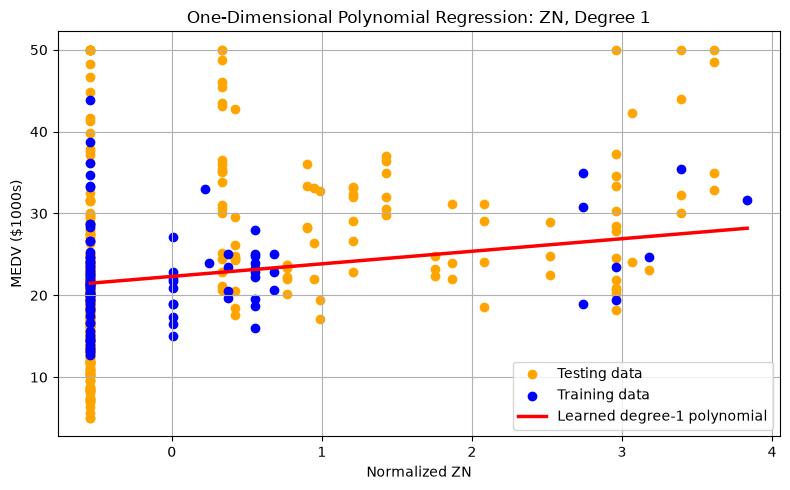

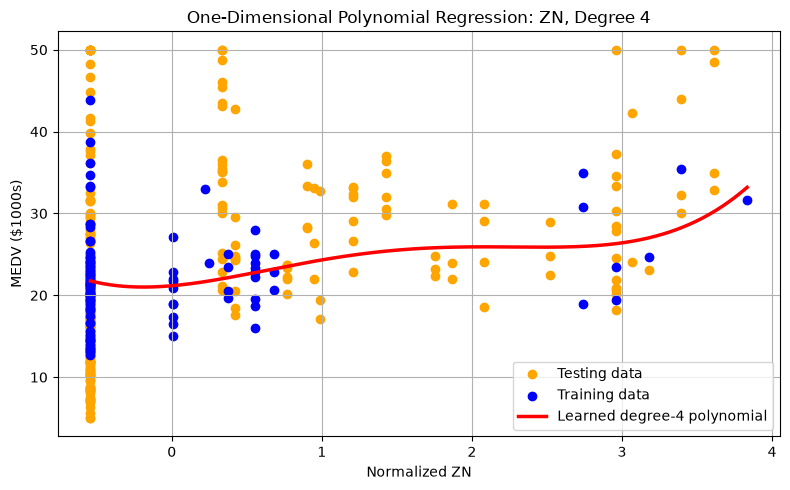

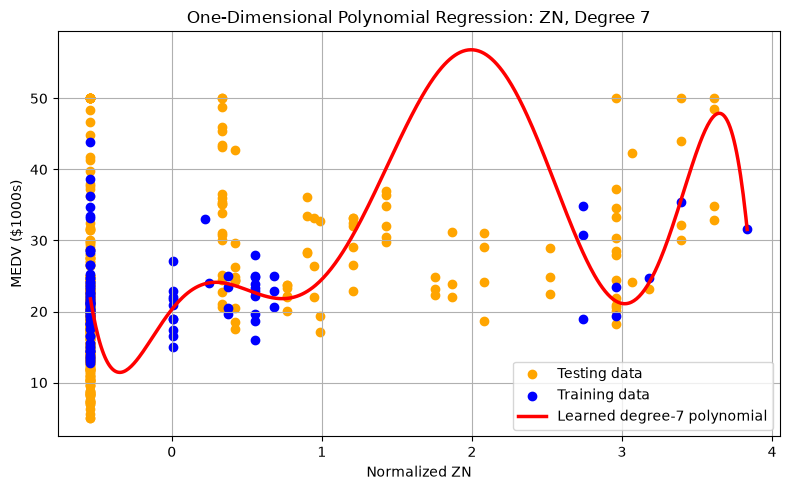

In [117]:
# degrees selected to show low, intermediate, and high polynomial complexity
degrees_to_visualize = [1,4,7]
one_d_res = []

for degree in degrees_to_visualize:
    result = polynomial_regression_1d_vis(
        X_train=X_train,
        target_train=target_train,
        X_test=X_test,
        target_test=target_test,
        degree=degree,
        feature_index=1
    )

    one_d_res.append(result)

In [118]:
one_d_res_table = pd.DataFrame([
    {
        "degree": result["degree"],
        "training_rmse": result["training_rmse"],
        "testing_rmse": result["testing_rmse"],
        "rank": result["rank"]
    }
    for result in one_d_res
])

one_d_res_table

,degree,training_rmse,testing_rmse,rank
0,1,5.695083,9.352257,2
1,4,5.650579,9.389718,5
2,7,5.500617,10.423300,8


### Results

The plots use the normalized second feature, ZN, to predict MEDV in its original units of thousands of dollars. Degrees 1, 4, and 7 were selected to demonstrate low, intermediate, and high polynomial complexity.

The degree 1 model produces a straight line with a small positive slope, indicating that higher values of ZN are generally associated with higher predicted MEDV. However, the data points are widely scattered around the line, showing that ZN alone cannot explain most of the variation in housing value. As shown in the table, the training RMSE is 5.695 and the testing RMSE is 9.352 thousand dollars.

The degree 4 model introduces moderate curvature while remaining relatively smooth. Its training RMSE decreases slightly to 5.651, while its testing RMSE is 9.390 thousand dollars. Therefore, the additional polynomial terms improve the fit to the training data only slightly but they do not improve generalization compared to the degree 1 model.

The degree 7 model produces a highly oscillating curve, particularly in regions containing fewer training points. For example, the model predicts a large peak around normalized ZN = 2 that is not supported by the surrounding data. Although its training RMSE decreases to 5.501, its testing RMSE increases to 10.423 thousand dollars. This difference indicates overfitting: the model follows variations in the training data more closely but performs worse on unseen testing data.

Of the models tested, degree 1 has the lowest testing RMSE. This suggests that the additional complexity of the higher degree polynomials is not useful when only ZN is used as the input feature.

#### Part 1(d)

A degree 8 polynomial using only the 2nd feature (ZN) has the form 
$$
\hat{t}
=
w_0+w_1z+w_2z^2+\cdots+w_8z^8
$$
and a basis vector
$$
\boldsymbol{\phi}_8(z)
=
[1,z,z^2,\ldots,z^8]
$$

so the model contains nine weights, including the bias weight. 
As we found previously, a high-degree polynomial can produce large and unstable weights, so L2 regularization will be used because it will add a penalty proportional to the squared magnitude of the non-bias weights:

$$
J(\mathbf{w})
=
\frac{1}{2}
\left\|
\mathbf{t}-\boldsymbol{\Phi}\mathbf{w}
\right\|^2
+
\frac{\lambda}{2}\mathbf{w}^{T}\mathbf{R}\mathbf{w},
\qquad
\mathbf{R}
=
\operatorname{diag}(0,1,1,\ldots,1)
$$

The corresponding ridge regression solution is 

$$
\mathbf{w}
=
\left(
\boldsymbol{\Phi}^{T}\boldsymbol{\Phi}
+
\lambda\mathbf{R}
\right)^{-1}
\boldsymbol{\Phi}^{T}\mathbf{t}
$$

Here, $\mathbf R=\operatorname{diag}(0,1,\ldots,1)$ is the regularization matrix. Its first diagonal entry is zero so that the bias weight $w_0$ is not regularized, while the remaining weights are penalized.

Increasing $\lambda$ increases the penalty that is added to the large weights, which is meant to reduce overfitting and improve numerical stability. However, an excessively large value can make the model underfit, so we will find a  $\lambda$ that balances this well. 

10-fold cross-validation is used to select $\lambda$. The 100 training samples are randomly divided into ten folds of ten samples. For each value of $\lambda$, the model is trained ten times: nine folds are used for fitting and the remaining fold is used for validation. Each fold is used as the validation set once. The average validation RMSE is then calculated, and the value of $\lambda$ with the lowest average validation RMSE is selected.

In [119]:
def polynomial_regression_reg(X_train, target_train, degree=8, feature_index=1, lambdas=(0, 0.01, 0.1, 1, 10, 100, 1000), number_of_folds=10, random_seed=42):
    # use the 10 fold cross validation to select the constant for L2 regulatization

    # select normalized ZN feature
    x_train_1d = X_train[:, feature_index: feature_index+1]
    
    # Shuffle reproducibly before dividing the data into folds
    rng = np.random.default_rng(random_seed)
    shuffled_indices = rng.permutation(x_train_1d.shape[0])
    
    # There are 100 samples, so each of the 10 folds has 10 samples
    folds = np.array_split(shuffled_indices, number_of_folds)

    cv_results = []

    # Evaluate every candidate regularization value
    for regularization in lambdas:
        fold_validation_rmse = []

        # Use each fold as the validation set once
        for validation_fold_index in range(number_of_folds):
            validation_indices = folds[validation_fold_index]

            fitting_indices = np.concatenate([
                folds[fold_index]
                for fold_index in range(number_of_folds)
                if fold_index != validation_fold_index
            ])

            # Construct degree 8 design matrices
            Phi_fitting = polynomial_design_matrix(x_train_1d[fitting_indices], degree)
            Phi_validation = polynomial_design_matrix(x_train_1d[validation_indices], degree)

            fitting_targets = target_train[fitting_indices]
            validation_targets = target_train[validation_indices]

            number_of_basis_functions = Phi_fitting.shape[1]

            if regularization == 0:
                # Ordinary least squares for the unregularized model
                weights, residuals, rank, singular_values = np.linalg.lstsq(Phi_fitting, fitting_targets, rcond=None)

            else:
                # L2 regularization can be implemented by augmenting the least-squares system with sqrt(lambda) * I
                # Penalize polynomial coefficients, but not the bias weight
                penalty_matrix = np.eye(number_of_basis_functions)
                penalty_matrix[0, 0] = 0.0

                penalty_matrix = np.sqrt(regularization) * penalty_matrix

                augmented_Phi = np.vstack([ Phi_fitting, penalty_matrix])

                augmented_targets = np.concatenate([fitting_targets, np.zeros(number_of_basis_functions)])

                weights, residuals, rank, singular_values = np.linalg.lstsq(augmented_Phi, augmented_targets, rcond=None)

            # Predict the targets in the validation fold
            validation_predictions = Phi_validation @ weights

            validation_rmse = rms_error( validation_targets, validation_predictions)
            fold_validation_rmse.append(validation_rmse)

        # Average the validation error over all ten folds
        cv_results.append({
            "lambda": regularization,
            "average_validation_rmse": np.mean(fold_validation_rmse),
            "validation_rmse_std": np.std(fold_validation_rmse)
        })

    cv_results_table = pd.DataFrame(cv_results)

    # Choose the lambda with the smallest average validation RMSE
    best_row_index = cv_results_table["average_validation_rmse"].idxmin()
    best_lambda = cv_results_table.loc[best_row_index, "lambda"]

    return cv_results_table, best_lambda

In [120]:
regularization_values = [0, 0.01, 0.1, 1, 10, 100, 1000]

cv_results_table, best_lambda = polynomial_regression_reg(
    X_train=X_train,
    target_train=target_train,
    degree=8,
    feature_index=1,
    lambdas=regularization_values,
    number_of_folds=10,
    random_seed=42
)

cv_results_table

,lambda,average_validation_rmse,validation_rmse_std
0,0.00,12.419501,20.675931
1,0.01,6.467606,3.528897
2,0.10,9.017750,10.237303
3,1.00,9.813756,11.943619
4,10.00,10.169805,12.603486
5,100.00,8.832707,8.669892
6,1000.00,6.565337,2.777039


In [121]:
print(f"Selected regularization constant: lambda = {best_lambda}")

Selected regularization constant: lambda = 0.01


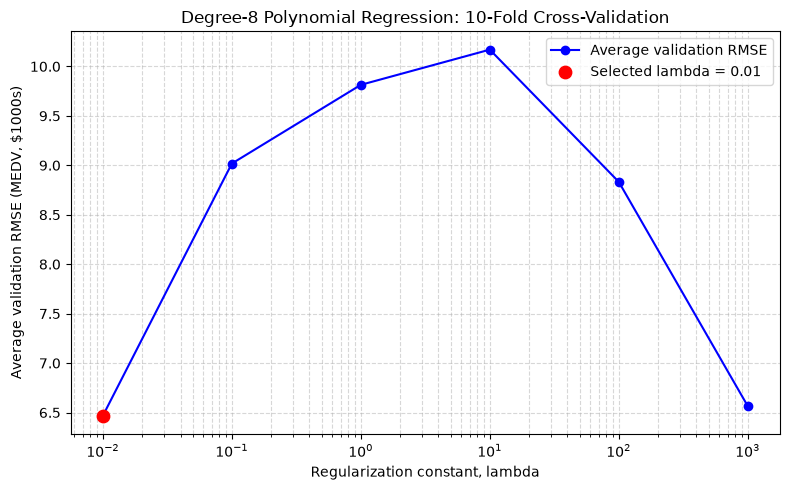

Unregularized average validation RMSE (lambda = 0): 12.420 thousand dollars


In [122]:
# Separate the unregularized result because log(0) is undefined
unregularized_rmse = cv_results_table.loc[cv_results_table["lambda"] == 0, "average_validation_rmse"].iloc[0]

positive_lambda_results = cv_results_table[cv_results_table["lambda"] > 0]

fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogx(
    positive_lambda_results["lambda"],
    positive_lambda_results["average_validation_rmse"],
    color="blue",
    marker="o",
    label="Average validation RMSE"
)

# Highlight the selected lambda if it is positive
if best_lambda > 0:
    best_rmse = cv_results_table.loc[
        cv_results_table["lambda"] == best_lambda,
        "average_validation_rmse"
    ].iloc[0]

    ax.scatter(
        best_lambda,
        best_rmse,
        color="red",
        s=80,
        zorder=3,
        label=f"Selected lambda = {best_lambda:g}"
    )

ax.set_title("Degree-8 Polynomial Regression: 10-Fold Cross-Validation")
ax.set_xlabel("Regularization constant, lambda")
ax.set_ylabel("Average validation RMSE (MEDV, $1000s)")

ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

print(
    "Unregularized average validation RMSE "
    f"(lambda = 0): {unregularized_rmse:.3f} thousand dollars"
)

### Results

The ten-fold cross-validation results show that $\lambda=0.01$ should be selected, since it produced the lowest average validation RMSE of approximately $6.468$ thousand dollars. In comparison, the unregularized degree 8 model, corresponding to $\lambda=0$, had a considerably larger average validation RMSE of $12.420$ thousand dollars. This indicates that the unregularized high degree polynomial is unstable and overfits the limited training data, while a small amount of L2 regularization improves its performance on unseen validation samples.

The validation error increased for intermediate values of $\lambda$, reaching approximately $10.170$ thousand dollars at $\lambda=10$. It then decreased again for very large regularization values, reaching $6.565$ thousand dollars at $\lambda=1000$. Since the bias is not regularized, a very large $\lambda$ shrinks the polynomial coefficients toward zero while retaining the bias. The resulting model approaches a constant prediction near the average training MEDV. This constant model performs reasonably because ZN alone has limited predictive ability. Nevertheless, $\lambda=0.01$ produced the lowest average validation RMSE among the tested values and was therefore selected.

### Part 2(e)

Gaussian basis function regression represents each input using its distance from a collection of centers. Each center $\mathbf{c}_j$ is selected from the normalized training data.

For input vector $\mathbf{x}$, the Gaussian basis function associated with center $\mathbf{c}_j$ is

$$
\phi_j(\mathbf{x})
=
\exp\left(
-\frac{\lVert\mathbf{x}-\mathbf{c}_j\rVert^2}
{2\sigma^2}
\right)
$$

where $\sigma$ controls the width of the Gaussian. Because the input features are standardized to comparable scales, $\sigma=1$ is used as a fixed Gaussian width.

For $K$ Gaussian centers, the basis vector is

$$
\boldsymbol{\phi}(\mathbf{x})
=
[1,\phi_1(\mathbf{x}),\phi_2(\mathbf{x}),\ldots,\phi_K(\mathbf{x})]
$$

The first value is the bias basis function. Therefore, a model with $K$ Gaussian basis functions has $K+1$ learned weights, including the bias weight.

The prediction is a linear combination of the Gaussian basis functions:

$$
\hat{t}
=
w_0+\sum_{j=1}^{K}w_j\phi_j(\mathbf{x}).
$$

The centers are selected by generating a random permutation of the 100 training samples and choosing the first $K$ samples. A fixed random seed is used to make the results reproducible. Models are fitted using $K=5,15,25,\ldots,95$ Gaussian basis functions without regularization, as shown below.

In [123]:
def gaussian_design_matrix(X, centers, sigma=1.0):
    # calculate difference between every input and every center 
    differences = X[:, np.newaxis, :]- centers[np.newaxis, :, :]

    # caluclate the squared Euclidean distance from every input to every center 
    squared_distances = np.sum(differences**2, axis=2)

    # evaluate Gaussian basis function 
    gaussian_basis = np.exp(-squared_distances/(2*sigma**2))
    # add the bias basis function as the first column 
    bias_column = np.ones((X.shape[0],1))

    return np.hstack([bias_column, gaussian_basis])

def gaussian_regression(X_train, target_train, X_test, target_test, basis_counts=range(5,100,10), sigma=1.0, random_seed=42):
    # fit Gaussian basis function regression model for varying number of basis functions
    
    # randomly order the training samples for center selection
    rng = np.random.default_rng(random_seed)
    center_order = rng.permutation(X_train.shape[0])

    res = []
    learned_weights = {}

    for num_basis_functions in basis_counts:
        # select the first K points as the center of basis functions 
        center_indicies = center_order[:num_basis_functions] 
        centers = X_train[center_indicies]

        # construct training and testing design matrices
        Phi_train = gaussian_design_matrix(X_train, centers, sigma)
        Phi_test = gaussian_design_matrix(X_test, centers, sigma)
        # calculate weights that minimize the sum of squared error 
        weights, residuals, rank, singular_values = (np.linalg.lstsq(Phi_train, target_train, rcond=None))
        # multiply the matricies to determine the predicted values 
        train_pred = Phi_train @ weights 
        test_pred = Phi_test @ weights 
        # calulate rms error 
        training_rmse = rms_error(target_train, train_pred)
        testing_rmse = rms_error(target_test, test_pred)
        # append results 
        res.append({
            "number_of_basis_functions": num_basis_functions,
            "number_of_parameters": Phi_train.shape[1],
            "training_rmse": training_rmse,
            "testing_rmse": testing_rmse,
            "matrix_rank": rank
        })
        # store the learned weights per degree of polynomial
        learned_weights[num_basis_functions] = weights
    # visualize in a table
    res_table = pd.DataFrame(res)
    return res_table, learned_weights 

In [124]:
basis_counts = range(5, 100, 10)

gaussian_results_table, gaussian_weights = gaussian_regression(
    X_train=X_train,
    target_train=target_train,
    X_test=X_test,
    target_test=target_test,
    basis_counts=basis_counts,
    sigma=1.0,
    random_seed=42
)

gaussian_results_table

,number_of_basis_functions,number_of_parameters,training_rmse,testing_rmse,matrix_rank
0,5,6,5.265364,9.866252,6
1,15,16,4.789689,9.820891,16
2,25,26,3.716045,9.775793,26
3,35,36,3.445260,9.769472,36
4,45,46,3.007498,9.791093,46
5,55,56,2.885384,9.847719,56
6,65,66,2.251161,9.763676,66
7,75,76,2.010503,9.725348,76
8,85,86,1.363693,9.725452,86
9,95,96,0.514223,10.140094,96


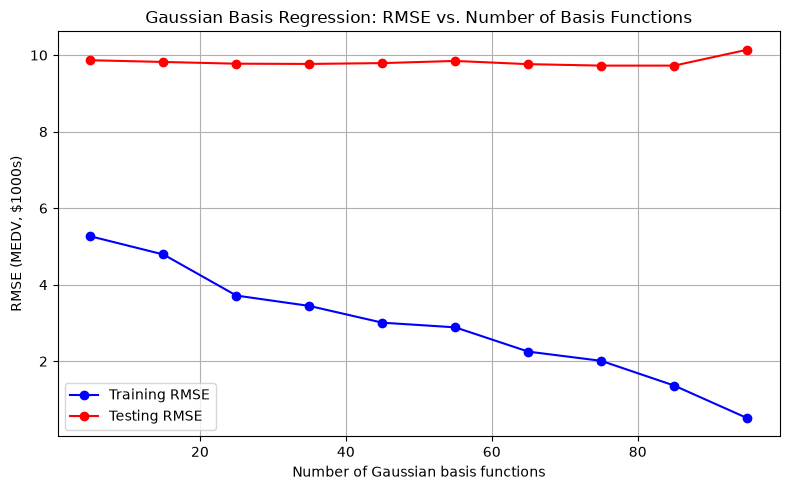

In [125]:
# plot training and testing RMSE in the original MEDV units
fig, ax = plt.subplots(figsize=(8, 5))

# training error
ax.plot(
    gaussian_results_table["number_of_basis_functions"],
    gaussian_results_table["training_rmse"],
    color="blue",
    marker="o",
    label="Training RMSE"
)

# testing error
ax.plot(
    gaussian_results_table["number_of_basis_functions"],
    gaussian_results_table["testing_rmse"],
    color="red",
    marker="o",
    label="Testing RMSE"
)

# grid cosmetic changes
ax.set_title("Gaussian Basis Regression: RMSE vs. Number of Basis Functions",)
ax.set_xlabel("Number of Gaussian basis functions")
ax.set_ylabel("RMSE (MEDV, $1000s)")

ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

### Results

As shown in the plot above, as the number of Gaussian basis functions increases, the training RMSE decreases steadily from approximately $5.265$ thousand dollars with 5 basis functions to $0.514$ thousand dollars with 95 basis functions. This occurs because adding more centers gives the model greater flexibility so that it is able to fit the training samples better.

In contrast, the testing RMSE remains relatively constant at approximately $9.7$–$9.9$ thousand dollars for most values of $K$. Models with very few basis functions may initially underfit the training data, but increasing $K$ substantially improves only the training fit. The lowest testing RMSE is approximately $9.725$ thousand dollars at $K=75$, although the result at $K=85$ is nearly identical. At $K=95$, the training RMSE decreases further while the testing RMSE increases to $10.140$ thousand dollars. This widening generalization gap indicates overfitting at higher values of $K$: the additional flexibility fits details specific to the training samples without improving performance on unseen data.

### Part 2(f)

L2-regularized regression with Gaussian basis functions is implemented using all 13 normalized input features. The model uses 90 Gaussian basis functions, with centers selected from the fitting samples in each cross-validation fold.

For input $\mathbf{x}$ and center $\mathbf{c}_j$, Gaussian basis function $j$ is

$$
\phi_j(\mathbf{x})
=
\exp\left(
-\frac{
\lVert\mathbf{x}-\mathbf{c}_j\rVert^2
}{
2\sigma^2
}
\right)
$$

where $\sigma=1$ is used as a fixed Gaussian width after standardizing the input features.

With 90 Gaussian basis functions, the prediction is

$$
\hat{t}
=
w_0+\sum_{j=1}^{90}w_j\phi_j(\mathbf{x}).
$$

Therefore, the model contains 91 parameters: 90 Gaussian weights and one bias weight.

Following conventional ridge regression, the bias weight is not regularized. The objective function is

$$
J(\mathbf{w})
=
\frac{1}{2}
\left\lVert
\mathbf{t}-\boldsymbol{\Phi}\mathbf{w}
\right\rVert^2
+
\frac{\lambda}{2}
\sum_{j=1}^{90}w_j^2
$$

The regularization matrix is

$$
\mathbf{R}
=
\operatorname{diag}(0,1,1,\ldots,1)
$$

where the first zero excludes the bias from the penalty. The ridge-regression solution is

$$
\mathbf{w}
=
\left(
\boldsymbol{\Phi}^{T}\boldsymbol{\Phi}
+
\lambda\mathbf{R}
\right)^{-1}
\boldsymbol{\Phi}^{T}\mathbf{t}
$$

Ten-fold cross-validation is used to select $\lambda$ from

$$
\{0,0.01,0.1,1,10,100,1000\}
$$

In each fold, 90 samples are used for fitting and as the Gaussian centers, while the remaining 10 samples are used only for validation. The average validation RMSE is calculated for each value of $\lambda$, and the value with the lowest average validation RMSE is selected.

In [126]:
def gaussian_regression_reg(X_train, target_train, number_of_basis_functions=90, lambdas=(0, 0.01, 0.1, 1, 10, 100, 1000), number_of_folds=10, sigma=1.0, random_seed=42):
    # use the 10 fold cross validation to select the constant for L2 regulatization
    
    # Shuffle reproducibly before dividing the data into folds
    rng = np.random.default_rng(random_seed)
    shuffled_indices = rng.permutation(X_train.shape[0])
    
    # There are 100 samples, so each of the 10 folds has 10 samples
    folds = np.array_split(shuffled_indices, number_of_folds)

    cv_results = []

    # Evaluate every candidate regularization value
    for regularization in lambdas:
        fold_validation_rmse = []

        # Use each fold as the validation set once
        for validation_fold_index in range(number_of_folds):
            validation_indices = folds[validation_fold_index]

            fitting_indices = np.concatenate([
                folds[fold_index]
                for fold_index in range(number_of_folds)
                if fold_index != validation_fold_index
            ])

            # use 90 fitting sample as Gaussian centers 
            center_indices = fitting_indices[:number_of_basis_functions]
            centers = X_train[center_indices]

            # Construct degree 8 design matrices
            Phi_fitting = gaussian_design_matrix(X_train[fitting_indices], centers, sigma)
            Phi_validation = gaussian_design_matrix(X_train[validation_indices], centers, sigma)

            fitting_targets = target_train[fitting_indices]
            validation_targets = target_train[validation_indices]

            number_of_params = Phi_fitting.shape[1]

            if regularization == 0:
                # Ordinary least squares for the unregularized model
                weights, residuals, rank, singular_values = np.linalg.lstsq(Phi_fitting, fitting_targets, rcond=None)

            else:
                # L2 regularization can be implemented by augmenting the least-squares system with sqrt(lambda) * I
                # Penalize Gaussian weights, but not the bias weight
                penalty_matrix = np.eye(number_of_params)
                penalty_matrix[0, 0] = 0.0

                penalty_matrix = np.sqrt(regularization) * penalty_matrix

                augmented_Phi = np.vstack([ Phi_fitting, penalty_matrix])
                augmented_targets = np.concatenate([fitting_targets, np.zeros(number_of_params)])

                weights, residuals, rank, singular_values = np.linalg.lstsq(augmented_Phi, augmented_targets, rcond=None)

            # Predict the targets in the validation fold
            validation_predictions = Phi_validation @ weights

            validation_rmse = rms_error( validation_targets, validation_predictions)
            fold_validation_rmse.append(validation_rmse)

        # Average the validation error over all ten folds
        cv_results.append({
            "lambda": regularization,
            "average_validation_rmse": np.mean(fold_validation_rmse),
            "validation_rmse_std": np.std(fold_validation_rmse)
        })

    cv_results_table = pd.DataFrame(cv_results)

    # Choose the lambda with the smallest average validation RMSE
    best_row_index = cv_results_table["average_validation_rmse"].idxmin()
    best_lambda = cv_results_table.loc[best_row_index, "lambda"]

    return cv_results_table, best_lambda

In [127]:
gaussian_regularization_values = [0, 0.01, 0.1, 1, 10, 100, 1000]

gaussian_cv_results_table, best_gaussian_lambda = (
    gaussian_regression_reg(
        X_train=X_train,
        target_train=target_train,
        number_of_basis_functions=90,
        lambdas=gaussian_regularization_values,
        number_of_folds=10,
        sigma=1.0,
        random_seed=42
    )
)

gaussian_cv_results_table

,lambda,average_validation_rmse,validation_rmse_std
0,0.00,3.877770,1.318616
1,0.01,3.772254,1.195032
2,0.10,3.769211,1.104446
3,1.00,4.124865,1.238343
4,10.00,4.959560,1.663191
5,100.00,5.516831,1.836666
6,1000.00,5.671946,1.849365


In [128]:
print(
    "Selected Gaussian regularization constant: "
    f"lambda = {best_gaussian_lambda}"
)

Selected Gaussian regularization constant: lambda = 0.1


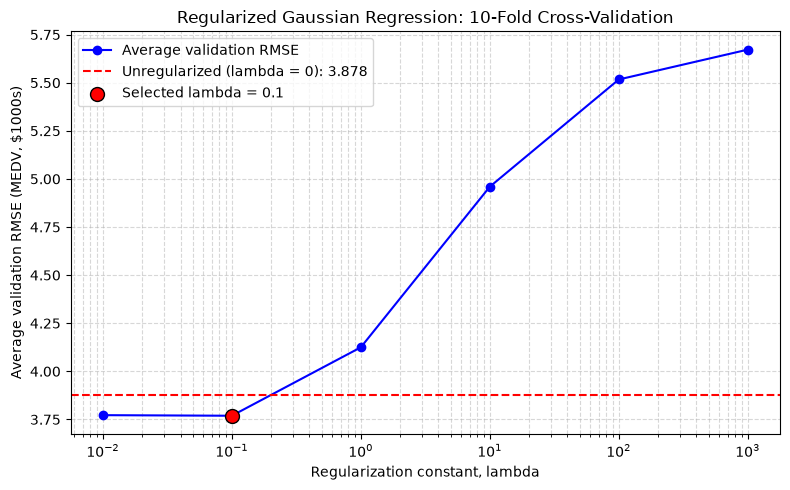

Unregularized average validation RMSE (lambda = 0): 3.878 thousand dollars


In [129]:
unregularized_gaussian_rmse = gaussian_cv_results_table.loc[gaussian_cv_results_table["lambda"] == 0, "average_validation_rmse"].iloc[0]

positive_gaussian_results = gaussian_cv_results_table[gaussian_cv_results_table["lambda"] > 0]

#plotting code
fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogx(
    positive_gaussian_results["lambda"],
    positive_gaussian_results["average_validation_rmse"],
    color="blue",
    marker="o",
    label="Average validation RMSE"
)


# unreguarlized (lambda = 0 baseline)
ax.axhline(
    y=unregularized_gaussian_rmse,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=(
        "Unregularized "
        f"(lambda = 0): {unregularized_gaussian_rmse:.3f}"
    )
)

# Highlight the selected lambda
if best_gaussian_lambda > 0:
    best_gaussian_rmse = gaussian_cv_results_table.loc[
        gaussian_cv_results_table["lambda"]
        == best_gaussian_lambda,
        "average_validation_rmse"
    ].iloc[0]

    ax.scatter(
        best_gaussian_lambda,
        best_gaussian_rmse,
        color="red",
        s=100,
        zorder=3,
        edgecolor="black",
        label=f"Selected lambda = {best_gaussian_lambda:g}"
    )

ax.set_title(
    "Regularized Gaussian Regression: 10-Fold Cross-Validation"
)

ax.set_xlabel("Regularization constant, lambda")
ax.set_ylabel("Average validation RMSE (MEDV, $1000s)")

ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

print(
    "Unregularized average validation RMSE "
    f"(lambda = 0): {unregularized_gaussian_rmse:.3f} "
    "thousand dollars"
)

### Results

The unregularized Gaussian model, corresponding to $\lambda=0$, produced an average validation RMSE of approximately $3.878$ thousand dollars, shown as the red dashed line in the figure above. Introducing a small amount of L2 regularization slightly improved validation performance: the lowest average validation RMSE was approximately $3.769$ thousand dollars at $\lambda=0.1$. The result for $\lambda=0.01$ was nearly identical, with an average validation RMSE of approximately $3.772$ thousand dollars.

For regularization values greater than $0.1$, the average validation error increased. In particular, the validation RMSE increased to approximately $4.125$ thousand dollars at $\lambda=1$ and continued increasing to $5.672$ thousand dollars at $\lambda=1000$. This indicates that strong regularization shrinks the Gaussian basis weights too much and causes the model to underfit.

Based on the minimum average validation RMSE, I would select $\lambda=0.1$ as the regularization constant. Although the results for $\lambda=0.01$ and $\lambda=0.1$ are nearly identical, $\lambda=0.1$ produces the smallest average error among the tested values.